# Imports

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from numba import njit
import json

# Parameters

In [73]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    total_depth_sample = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples 
    params["simulation"]["total_depth_sample"] = total_depth_sample #depth per sample in m
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])
    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Total depth samples: ", total_depth_sample)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [74]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  3200
Total depth samples:  3.125e-06
Step size:  4.166666666666667e-09 s
Maximal acquisition depth: 0.01 m
Lateral step:  2.5e-05 m


## Old parameters

In [52]:
# array_length = 128 #elements
# aperture = 0.8

# pitch = 1e-4 #m
# frequency = 1.5e+7 #hz
# c = 1500 #m/s
# sampling_rate = 16 * frequency  #hz

# object_depth = 3e-3 #m
# object_position = 7e-3 #m

# object2_depth = 4e-3 #m
# object2_position = 8e-3 #m

# object3_depth = 3.1e-3 #m
# object3_position = 7.5e-3 #m

# object4_depth = 9e-3 #m
# object4_position = 5e-3 #m

# total_depth = 2e-2 #m

# step_size = 1 / sampling_rate #s
# samples = int( sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
# total_depth_sample = (total_depth / 2) / samples  #total depth in m / number of samples = depth per sample
# lateral_resolution = 2048

# pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #position sampling
# # time = np.linspace(start=0, stop=step_size, num=samples) #time sampling
# time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling

# print("Apperture: ", aperture)
# print("Samples: ", samples)
# print("Total depth samples: ", total_depth_sample)
# print("Step size: ", step_size, "s")
# print("Maximal acquisition depth:", c*(step_size*samples) / 2, "m")

## Objects

In [53]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(params["array"]["length"])
        self.rf_matrix = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.effective_array_length = 0
        self.effective_angle = 0

In [ ]:
objects = []

for reflector in params["objects"]:
    objects.append(Objects(reflector["depth"], reflector["position"]))

# Signals

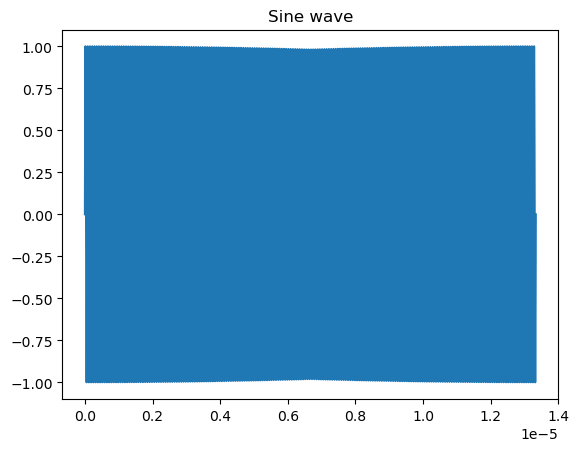

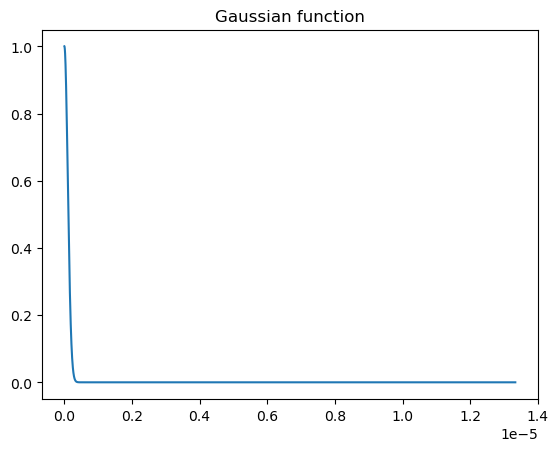

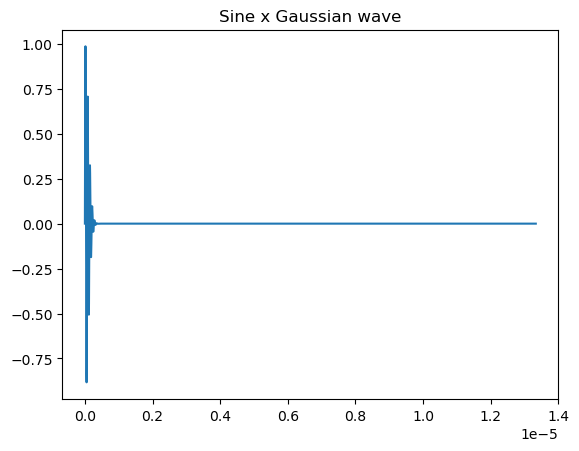

In [55]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep )#+ np.pi/2)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

wave = sine_wave(params['wave']['frequency'], time)
plt.plot(time, wave)
plt.title("Sine wave")
plt.show()

wave = gaussian_function(time, gaussian_std)
plt.plot(time, wave)
plt.title("Gaussian function")
plt.show()

wave = generate_wave(params['wave']['frequency'], time, gaussian_std)
plt.plot(time, wave)
plt.title("Sine x Gaussian wave")
plt.show()

In [56]:
wave.shape

(3200,)

# DAS (delay and sum)

In [57]:
def delay_function(object_depth, object_position, speed_sound, array_position, pitch):
    return (object_depth / speed_sound) + np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound

In [58]:
def get_delays(objects, c, pitch, array_length, destination="./data/csv/delays/"):
    for i in range(0, len(objects)):
        for j in range(0, array_length):
            objects[i].delays[j] = delay_function(object_depth=objects[i].depth, object_position=objects[i].position, speed_sound=c, array_position=j, pitch=pitch)

        objects[i].delays.tofile(f"{destination}delay_matrix_object{i+1}.csv", sep=",")


get_delays(objects, params['wave']['c'], params['array']['pitch'], params['array']['length'])

## Showing delay results

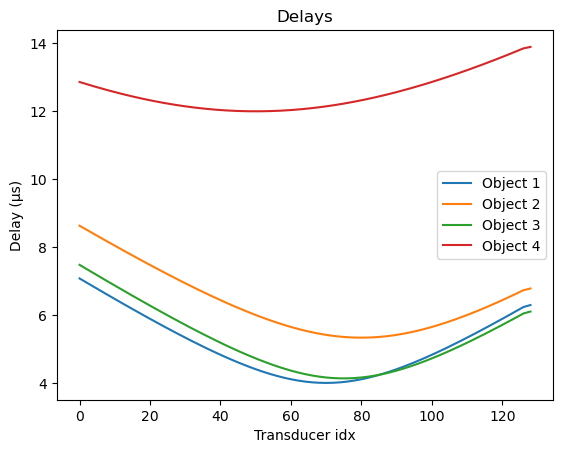

In [59]:
plt.figure()    
for i in range(0, len(objects)):
    plt.plot(pos, objects[i].delays*1e6, label = f"Object {i+1}")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Find object effective aperture 

In [60]:
def find_object_effective_aperture(objects, aperture):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture
        print(f"Object {i+1} effective array length: {objects[i].effective_array_length} m") 

find_object_effective_aperture(objects, params["array"]["aperture"])

Object 1 effective array length: 0.00375 m
Object 2 effective array length: 0.005 m
Object 3 effective array length: 0.0038749999999999995 m
Object 4 effective array length: 0.011249999999999998 m


## Adding Wave

In [61]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return np.cos(np.abs(current_object.position - current_transducer * pitch) / current_object.effective_array_length) ** 18

In [62]:
def get_rf_matrices(objects, frequency, time, array_length, pitch, gaussian_std, samples, destination="./data/csv/rf_data/"):
    rf_matrix_summed = np.zeros((samples, array_length))

    for i in range(0, len(objects)):
        for j in range(array_length):
            #for each transducer, generate the wave with the corresponding delay
            objects[i].rf_matrix[:, j] = generate_wave(frequency, time - objects[i].delays[j], gaussian_std) * is_in_transducer_range(objects[i], j, pitch)
        
        objects[i].rf_matrix.tofile(f"{destination}rf_matrix_object{i+1}.csv", sep=",")    
        rf_matrix_summed += objects[i].rf_matrix

    rf_matrix_summed.tofile(f"{destination}rf_matrix_summed.csv", sep=",")
    return rf_matrix_summed

In [63]:
rf_matrix_summed = get_rf_matrices(objects, params['wave']['frequency'], time, params['array']['length'], params["array"]["pitch"], gaussian_std, params["simulation"]["samples"])

## Showing wave results

In [64]:
rf_matrix_summed.shape

(3200, 128)

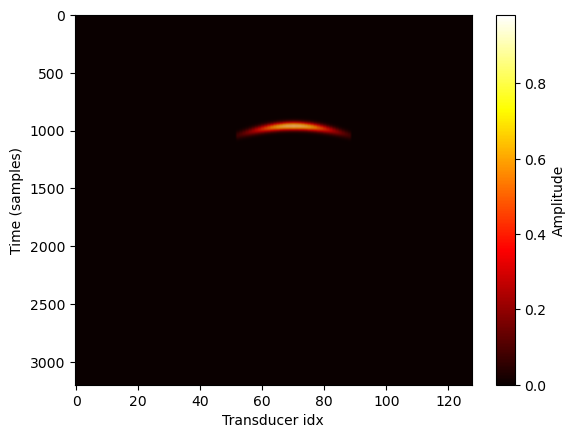

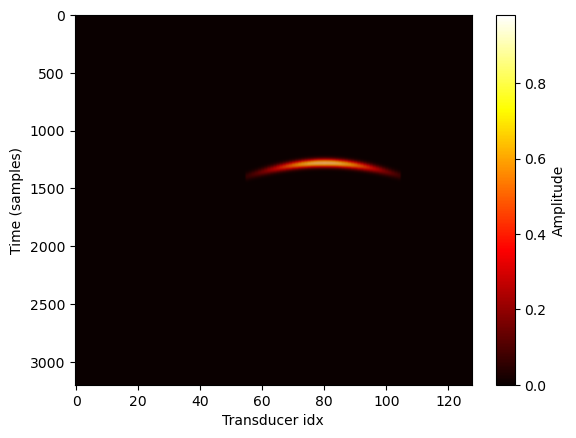

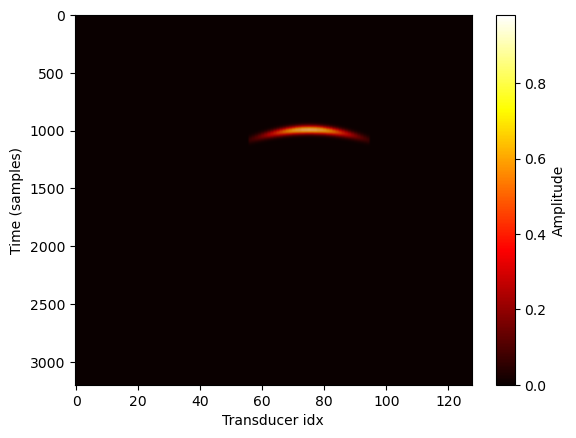

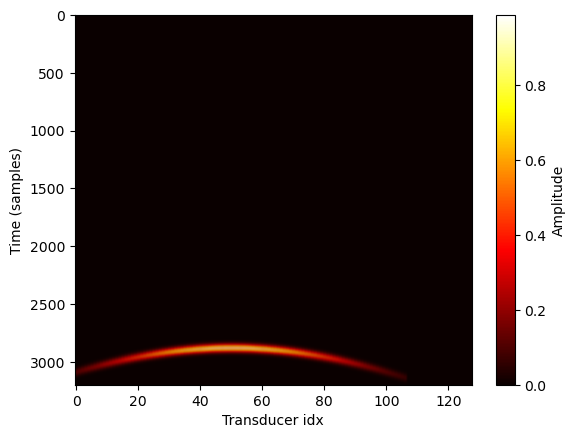

In [65]:
for i in range(0, len(objects)):
    plt.figure()
    plt.imshow(abs(objects[i].rf_matrix), cmap='hot', aspect='auto')
    plt.xlabel("Transducer idx")
    plt.ylabel("Time (samples)")
    plt.savefig(f"./data/images/rf_matrix_object{i+1}.png")
    plt.colorbar(label="Amplitude")
    plt.show()

## Showing summed wave results

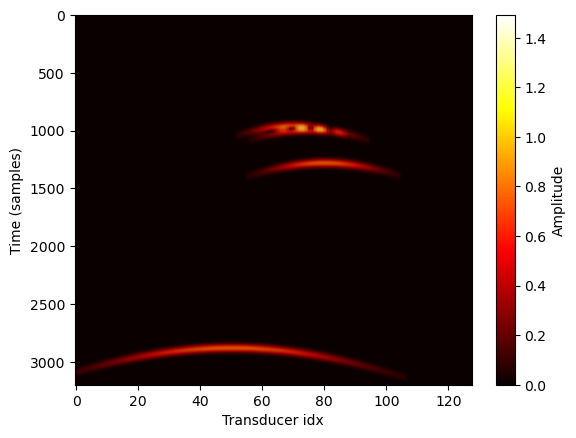

In [66]:
plt.imshow(abs(rf_matrix_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.savefig("./data/images/rf_matrix_summed.png")
plt.colorbar(label="Amplitude")
plt.show()

## Applying sum

### Beamforming

In [67]:
def beamforming(rf_matrix_summed, lateral_resolution, samples, total_depth_sample, pitch, c, array_length, sampling_rate):
    bf_matrix = np.zeros((samples, lateral_resolution))

    for j in tqdm (range(0, lateral_resolution), desc="Beamforming in progress..."):

        for k in range(0, samples):

            depth = total_depth_sample*k
            position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
            # we normalize the index to the total array length

            for l in range(0, array_length):

                delay = delay_function(object_depth=depth, object_position=position, speed_sound=c, array_position=l, pitch=pitch)
                delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                if delay_idx < samples:
                    bf_matrix[k,j] += rf_matrix_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)
    print("Beamforming done")
    return bf_matrix

### Beamforming numba

In [68]:
@njit(parallel=True)
def beamforming_opt(rf_matrix_summed, lateral_resolution, samples, total_depth_sample, pitch, c, array_length, sampling_rate):
    bf_matrix = np.zeros((samples, lateral_resolution))

    for j in range(0, lateral_resolution):
        if j % 10 == 0:
            print(f"Progress: {j}/{lateral_resolution}")

        for k in range(0, samples):

            depth = total_depth_sample*k
            position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
            # we normalize the index to the total array length

            for l in range(0, array_length):

                delay = (depth / c) + np.sqrt(depth**2 + (l * pitch - position)**2) / c
                delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                if delay_idx < samples:
                    bf_matrix[k,j] += rf_matrix_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)
    print("Beamforming done")
    return bf_matrix

In [69]:
bf_matrix = beamforming_opt(rf_matrix_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])

Progress: 0/512
Progress: 10/512
Progress: 20/512
Progress: 30/512
Progress: 40/512
Progress: 50/512
Progress: 60/512
Progress: 70/512
Progress: 80/512
Progress: 90/512
Progress: 100/512
Progress: 110/512
Progress: 120/512
Progress: 130/512
Progress: 140/512
Progress: 150/512
Progress: 160/512
Progress: 170/512
Progress: 180/512
Progress: 190/512
Progress: 200/512
Progress: 210/512
Progress: 220/512
Progress: 230/512
Progress: 240/512
Progress: 250/512
Progress: 260/512
Progress: 270/512
Progress: 280/512
Progress: 290/512
Progress: 300/512
Progress: 310/512
Progress: 320/512
Progress: 330/512
Progress: 340/512
Progress: 350/512
Progress: 360/512
Progress: 370/512
Progress: 380/512
Progress: 390/512
Progress: 400/512
Progress: 410/512
Progress: 420/512
Progress: 430/512
Progress: 440/512
Progress: 450/512
Progress: 460/512
Progress: 470/512
Progress: 480/512
Progress: 490/512
Progress: 500/512
Progress: 510/512
Beamforming done


In [70]:
#nukber of non null samples
non_null_samples = np.count_nonzero(bf_matrix)
print("Non null samples: ", non_null_samples)

Non null samples:  1637321


### Visualize beamformed image

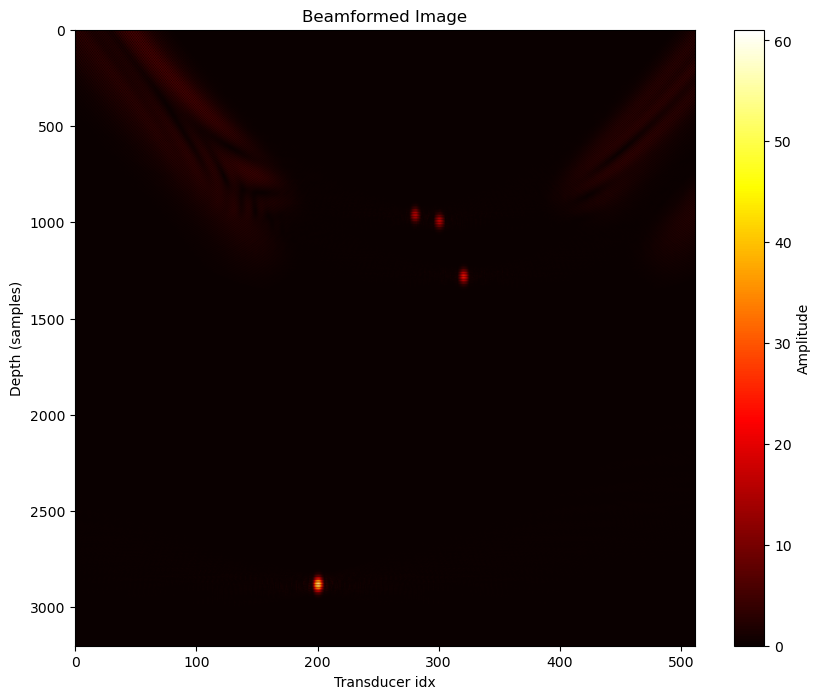

In [71]:
bf_matrix.tofile(f"./data/csv/bf_matrix.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_image.png")
plt.show()

# Explanation

## The Core Concept
The key insight is that if there was a **reflector at the pixel location:**
- Each transducer would have received a reflection at a specific delay time
- By looking up what was actually measured at those specific delay times
- And adding them together
- We get constructive interference where actual reflectors exist

This is the fundamental principle behind delay-and-sum beamforming.
When we align and sum the signals properly, reflections from real objects add constructively, while noise tends to cancel out.

Example Scenario:

Imagine a reflector at depth 5mm:

- For a centered transducer, the echo might arrive at 6.67 μs (5mm ÷ 1500 m/s × 2)
- For an off-center transducer, it would take slightly longer due to the diagonal path
- When we sum the signals at their correct delay times, the reflector "appears" in our image
- This technique essentially transforms time-domain signals into a spatial image, revealing the locations of reflectors in your imaging field